# Travel Expense Analytics System
**Course:** ICS 214 - IT Workshop

**Aim:** Analyze travel expenses to see where money is spent, compare planned budget with actual expense, and find useful insights.

**Tools used:** Python, Pandas, NumPy, Matplotlib

**Steps in this notebook**
1. Load and clean data
2. Expense categorization
3. Budget analysis
4. Statistical analysis
5. Data visualization
6. Travel expense reports

## Step 0: Import libraries

In [1]:
import pandas as pd              # for working with table data
import numpy as np               # for calculations
import matplotlib.pyplot as plt  # for charts

## Step 1: Expense Data Management (Load and Clean)
Each row is one expense: *Destination, Category, Planned Budget, Actual Expense* (in Rs).

> The data below is sample data typed directly in the code.


In [2]:
rows = [
    ("Goa",    "Transportation", 5000, 5600),
    ("Goa",    "Accommodation",  8000, 9500),
    ("Goa",    "Food",           4000, 4800),
    ("Goa",    "Sightseeing",    3000, 2500),
    ("Goa",    "Shopping",       2000, 3200),
    ("Manali", "Transportation", 7000, 6500),
    ("Manali", "Accommodation",  6000, 5800),
    ("Manali", "Food",           3500, 3900),
    ("Manali", "Sightseeing",    4000, 4600),
    ("Manali", "Shopping",       2500, 2000),
    ("Kerala", "Transportation", 6000, 6200),
    ("Kerala", "Accommodation",  7500, 7000),
    ("Kerala", "Food",           3500, 3300),
    ("Kerala", "Sightseeing",    3500, 3000),
    ("Kerala", "Shopping",       2000, None),   # missing value (on purpose, to show cleaning)
    ("Jaipur", "Transportation", 4500, 4200),
    ("Jaipur", "Accommodation",  5000, 5500),
    ("Jaipur", "Food",           3000, 3600),
    ("Jaipur", "Sightseeing",    2500, 2300),
    ("Jaipur", "Shopping",       3000, 3800),
    ("Goa",    "Food",           4000, 4800),   # duplicate row (on purpose, to show cleaning)
]

df = pd.DataFrame(rows, columns=["Destination", "Category", "Planned_Budget", "Actual_Expense"])
df.head()

,Destination,Category,Planned_Budget,Actual_Expense
0,Goa,Transportation,5000,5600.0
1,Goa,Accommodation,8000,9500.0
2,Goa,Food,4000,4800.0
3,Goa,Sightseeing,3000,2500.0
4,Goa,Shopping,2000,3200.0


In [3]:
print("Shape (rows, columns):", df.shape)
print()
print("Missing values in each column:")
print(df.isnull().sum())
print()
print("Duplicate rows:", df.duplicated().sum())

Shape (rows, columns): (21, 4)

Missing values in each column:
Destination       0
Category          0
Planned_Budget    0
Actual_Expense    1
dtype: int64

Duplicate rows: 1


In [4]:
# Cleaning: remove duplicate rows and rows with missing values
df = df.drop_duplicates()
df = df.dropna()

print("Shape after cleaning:", df.shape)

Shape after cleaning: (19, 4)


## Step 2: Expense Categorization
Spending is divided into 5 categories: Transportation, Accommodation, Food, Sightseeing, Shopping.
Here we add up the actual expense of each category.

In [5]:
category_total = df.groupby("Category")["Actual_Expense"].sum()
print(category_total)

Category
Accommodation     27800.0
Food              15600.0
Shopping           9000.0
Sightseeing       12400.0
Transportation    22500.0
Name: Actual_Expense, dtype: float64


## Step 3: Budget Analysis
Difference = Planned Budget - Actual Expense

- Difference is **positive** -> money saved
- Difference is **negative** -> budget overrun

In [6]:
df["Difference"] = df["Planned_Budget"] - df["Actual_Expense"]

# np.where works like if-else for the whole column
df["Status"] = np.where(df["Difference"] >= 0, "Saving", "Overrun")

df

,Destination,Category,Planned_Budget,Actual_Expense,Difference,Status
0,Goa,Transportation,5000,5600.0,-600.0,Overrun
1,Goa,Accommodation,8000,9500.0,-1500.0,Overrun
2,Goa,Food,4000,4800.0,-800.0,Overrun
3,Goa,Sightseeing,3000,2500.0,500.0,Saving
4,Goa,Shopping,2000,3200.0,-1200.0,Overrun
5,Manali,Transportation,7000,6500.0,500.0,Saving
6,Manali,Accommodation,6000,5800.0,200.0,Saving
7,Manali,Food,3500,3900.0,-400.0,Overrun
8,Manali,Sightseeing,4000,4600.0,-600.0,Overrun
9,Manali,Shopping,2500,2000.0,500.0,Saving


In [7]:
total_planned = df["Planned_Budget"].sum()
total_actual = df["Actual_Expense"].sum()
total_diff = total_planned - total_actual

print("Total planned budget :", total_planned)
print("Total actual expense :", total_actual)

if total_diff >= 0:
    print("Overall saving       :", total_diff)
else:
    print("Overall overrun      :", abs(total_diff))

print()
print("Number of Saving / Overrun expenses:")
print(df["Status"].value_counts())

Total planned budget : 83500
Total actual expense : 87300.0
Overall overrun      : 3800.0

Number of Saving / Overrun expenses:
Status
Overrun    10
Saving      9
Name: count, dtype: int64


## Step 4: Statistical Analysis
Total, average, minimum and maximum of actual expenses using NumPy.

In [8]:
expenses = df["Actual_Expense"].values   # convert column to a NumPy array

print("Total   expense:", np.sum(expenses))
print("Average expense:", round(np.mean(expenses), 2))
print("Minimum expense:", np.min(expenses))
print("Maximum expense:", np.max(expenses))

highest_category = category_total.idxmax()
print()
print("Highest spending category:", highest_category, "->", category_total.max())

Total   expense: 87300.0
Average expense: 4594.74
Minimum expense: 2000.0
Maximum expense: 9500.0

Highest spending category: Accommodation -> 27800.0


## Step 5: Data Visualization
Three charts: bar chart, pie chart, and planned vs actual comparison.

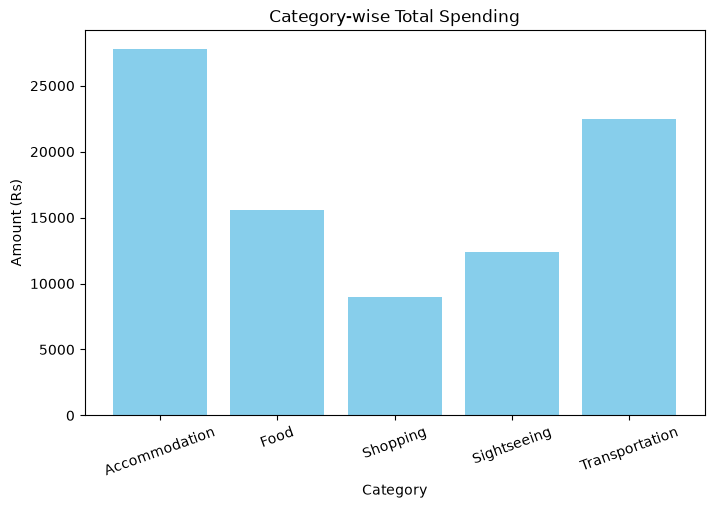

In [9]:
# Chart 1: Bar chart - category-wise total spending
plt.figure(figsize=(8, 5))
plt.bar(category_total.index, category_total.values, color="skyblue")
plt.title("Category-wise Total Spending")
plt.xlabel("Category")
plt.ylabel("Amount (Rs)")
plt.xticks(rotation=20)
plt.show()

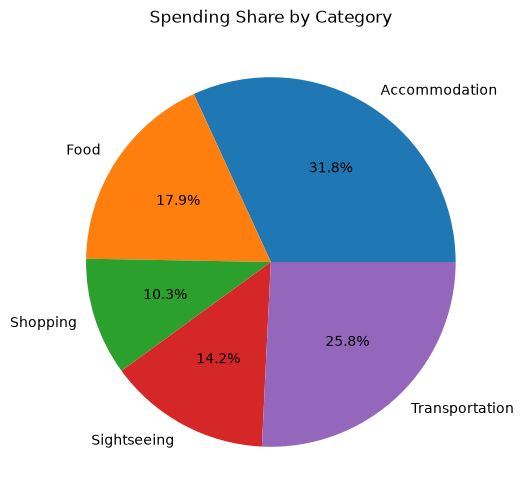

In [10]:
# Chart 2: Pie chart - share of each category in total spending
plt.figure(figsize=(6, 6))
plt.pie(category_total.values, labels=category_total.index, autopct="%1.1f%%")
plt.title("Spending Share by Category")
plt.show()

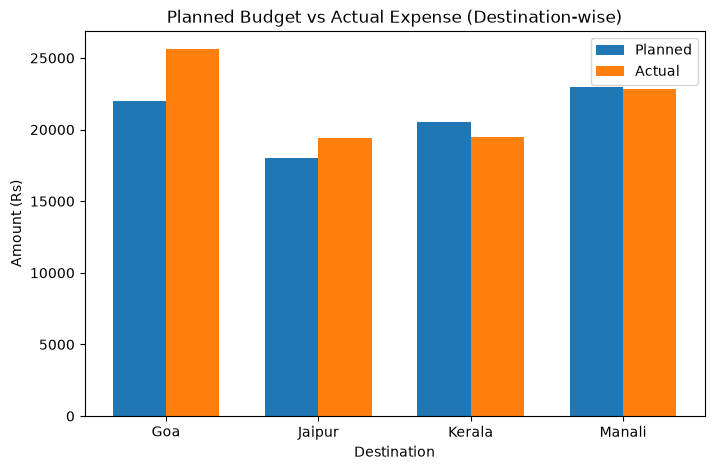

In [11]:
# Chart 3: Planned vs Actual for each destination
dest_total = df.groupby("Destination")[["Planned_Budget", "Actual_Expense"]].sum()

x = np.arange(len(dest_total))   # positions 0, 1, 2, 3
width = 0.35                     # width of each bar

plt.figure(figsize=(8, 5))
plt.bar(x - width/2, dest_total["Planned_Budget"], width, label="Planned")
plt.bar(x + width/2, dest_total["Actual_Expense"], width, label="Actual")
plt.xticks(x, dest_total.index)
plt.title("Planned Budget vs Actual Expense (Destination-wise)")
plt.xlabel("Destination")
plt.ylabel("Amount (Rs)")
plt.legend()
plt.show()

## Step 6: Travel Expense Reports

In [12]:
# Report 1: Destination-wise summary
dest_report = df.groupby("Destination")[["Planned_Budget", "Actual_Expense", "Difference"]].sum()
print("DESTINATION-WISE REPORT")
dest_report

DESTINATION-WISE REPORT


,Planned_Budget,Actual_Expense,Difference
Destination,,,
Goa,22000,25600.0,-3600.0
Jaipur,18000,19400.0,-1400.0
Kerala,20500,19500.0,1000.0
Manali,23000,22800.0,200.0


In [13]:
# Report 2: Category-wise summary
cat_report = df.groupby("Category")[["Planned_Budget", "Actual_Expense", "Difference"]].sum()
print("CATEGORY-WISE REPORT")
cat_report

CATEGORY-WISE REPORT


,Planned_Budget,Actual_Expense,Difference
Category,,,
Accommodation,26500,27800.0,-1300.0
Food,14000,15600.0,-1600.0
Shopping,7500,9000.0,-1500.0
Sightseeing,13000,12400.0,600.0
Transportation,22500,22500.0,0.0


## Conclusion

In [14]:
costliest_destination = dest_report["Actual_Expense"].idxmax()
worst_overrun = dest_report["Difference"].idxmin()

print("Costliest destination      :", costliest_destination)
print("Highest spending category  :", highest_category)
print("Destination with most overrun (or least saving):", worst_overrun)
print()
print("Suggestion: keep extra budget for the highest spending category.")

Costliest destination      : Goa
Highest spending category  : Accommodation
Destination with most overrun (or least saving): Goa

Suggestion: keep extra budget for the highest spending category.
